# Functional Complexity Analysis: XORable Subnetworks

This notebook analyzes the functional complexity of neural networks by measuring the number of XORable subnetworks. The functional complexity is defined as the ability of a network to form nonlinear input associations and represent complex decision boundaries.

## Definition of XORable Subnetwork

A subnetwork {I1, I2, O} is considered XORable if:

1. Four independent simulations are run with inputs: {(0,1), (1,1), (0,0), (1,0)}
2. The output responses from simulations 1 and 4 should be linearly separable from simulations 2 and 3
3. In other words: relative order of outputs from sim1 and sim4 should be larger than outputs from sim2 and sim3

## Experimental Design

We will:

1. **Load pre-trained networks** from adding_problem_1.ipynb (or train new ones if not available)
2. **Analyze functional complexity** by measuring XORable subnetworks in the trained models
3. **Compare complexity** between:
   - **SimpleNet**: Standard vanilla RNN
   - **Net**: RNN with excitatory/inhibitory separation

The pre-trained models have learned interesting computational structures from the adding problem task, which makes them ideal candidates for complexity analysis.


## 1. Setup and Imports


In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import itertools
from typing import List, Tuple, Dict
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

Using device: cuda


## 2. XOR Test Functions


In [2]:
from operator import is_, xor


def test_xor_subnetwork(model: nn.Module, input_neurons: List[int], output_neuron: int,
                       seq_len: int = 10, activation_strength: float = 1.0) -> Tuple[bool, List[float]]:
    """
    Test if a subnetwork {I1, I2, O} is XORable.

    Args:
        model: The neural network model
        input_neurons: List of two input neuron indices [I1, I2]
        output_neuron: Index of output neuron O
        seq_len: Length of the input sequence
        activation_strength: Strength of neuron activation

    Returns:
        is_xorable: Boolean indicating if the subnetwork is XORable
        outputs: List of output responses for the four input combinations
    """
    model.eval()

    # Four input combinations: (I1, I2) = (0,1), (1,1), (0,0), (1,0)
    input_combinations = [(0, 1), (1, 1), (0, 0), (1, 0)]
    outputs = []

    with torch.no_grad():
        for i1_val, i2_val in input_combinations:
            # Create input sequence
            input_seq = torch.zeros(seq_len, 1, model.input_size, device=device)

            # Activate input neurons at time 0
            if i1_val == 1 and input_neurons[0] < model.input_size:
                input_seq[0, 0, input_neurons[0]] = activation_strength
            if i2_val == 1 and input_neurons[1] < model.input_size:
                input_seq[0, 0, input_neurons[1]] = activation_strength

            # Forward pass
            if hasattr(model, 'lstm'):
                # For our custom models
                output, _, hidden = model(input_seq)
                # Get hidden state to extract neuron activity
                if isinstance(hidden, tuple):
                    hidden_states = hidden[0]  # (seq_len, batch, hidden_size)
                else:
                    hidden_states = hidden

                # Extract output neuron activity (use last time step)
                if output_neuron < hidden_states.shape[2]:
                    output_activity = hidden_states[-1, 0, output_neuron].item()
                else:
                    # If output_neuron index is beyond hidden size, use actual output
                    output_activity = output[-1, 0, 0].item()
            else:
                # For standard PyTorch models
                output, hidden = model(input_seq)
                output_activity = output[-1, 0, output_neuron].item()

            outputs.append(output_activity)

    xor_outputs = [outputs[0], outputs[3]]  # (0,1) and (1,0)
    and_or_outputs = [outputs[1], outputs[2]]  # (1,1) and (0,0)

    # Check if XOR outputs are linearly separable from AND/OR outputs
    is_xorable = (min(xor_outputs) > max(and_or_outputs)) or (max(xor_outputs) < min(and_or_outputs))

    return is_xorable, outputs


def measure_functional_complexity(model: nn.Module, max_input_neurons: int = None,
                                max_output_neurons: int = None, seq_len: int = 10) -> Dict:
    """
    Measure the functional complexity of a network by counting XORable subnetworks.

    Args:
        model: The neural network model
        max_input_neurons: Maximum number of input neurons to consider
        max_output_neurons: Maximum number of output neurons to consider
        seq_len: Length of input sequence for testing

    Returns:
        Dictionary containing complexity metrics
    """
    model.eval()

    # Determine network dimensions
    if max_input_neurons is None:
        max_input_neurons = min(model.input_size, 10)  # Limit for computational efficiency
    if max_output_neurons is None:
        max_output_neurons = min(model.hidden_size, 20)  # Test hidden neurons as outputs

    total_subnetworks = 0
    xorable_subnetworks = 0
    xorable_details = []

    # Generate all possible input neuron pairs
    input_pairs = list(itertools.combinations(range(max_input_neurons), 2))

    print(f"Testing {len(input_pairs)} input pairs with {max_output_neurons} output neurons...")

    # Test each combination of input pair and output neuron
    for i, (i1, i2) in enumerate(input_pairs):
        if i % 10 == 0:
            print(f"Progress: {i}/{len(input_pairs)} input pairs processed")

        for output_idx in range(max_output_neurons):
            total_subnetworks += 1

            # Test if this subnetwork is XORable
            is_xorable, response_outputs = test_xor_subnetwork(
                model, [i1, i2], output_idx, seq_len
            )

            if is_xorable:
                xorable_subnetworks += 1
                xorable_details.append({
                    'input_neurons': [i1, i2],
                    'output_neuron': output_idx,
                    'responses': response_outputs
                })

    complexity_ratio = xorable_subnetworks / total_subnetworks if total_subnetworks > 0 else 0

    return {
        'total_subnetworks': total_subnetworks,
        'xorable_subnetworks': xorable_subnetworks,
        'complexity_ratio': complexity_ratio,
        'xorable_details': xorable_details
    }


def measure_functional_complexity_batch(model: nn.Module, input_size: int = None,
                                output_size: int = None, seq_len: int = 10) -> Dict:
    """
    Measure the functional complexity of a network by counting XORable subnetworks.

    Args:
        model: The neural network model
        max_input_neurons: Maximum number of input neurons to consider
        max_output_neurons: Maximum number of output neurons to consider
        seq_len: Length of input sequence for testing

    Returns:
        Dictionary containing complexity metrics
    """
    model.eval()

    # Determine network dimensions
    # if max_input_neurons is None:
    #     max_input_neurons = min(model.input_size, 10)  # Limit for computational efficiency
    # if max_output_neurons is None:
    #     max_output_neurons = min(model.hidden_size, 20)  # Test hidden neurons as outputs

    xorable_ratio = 0.
    xorable_details = []

    # Generate all possible input neuron pairs
    input_pairs = list(itertools.combinations(range(input_size), 2))

    print(f"Testing {len(input_pairs)} input pairs with {output_size} output neurons...")
    input_combinations = [(0, 1), (1, 1), (0, 0), (1, 0)]
    # Test each combination of input pair and output neuron
    for i, (i1, i2) in enumerate(input_pairs):
        if i % 10 == 0:
            print(f"Progress: {i}/{len(input_pairs)} input pairs processed")
        model.eval()

        with torch.no_grad():
            # input_seq = torch.zeros(seq_len, len(input_combinations), input_size, device=device)
            input_seq = torch.randn(seq_len, len(input_combinations), input_size, device=device)/input_size
            for j, (i1_val, i2_val) in enumerate(input_combinations):
                # Create input sequence
                input_seq[:, j, i1] = i1_val
                input_seq[:, j, i2] = i2_val
            # Forward pass
            if hasattr(model, 'lstm'):
                # For our custom models
                output1, _, hidden = model(input_seq)
                # Get hidden state to extract neuron activity
                if isinstance(hidden, tuple):
                    hidden_states = hidden[0]  # (seq_len, batch, hidden_size)
                else:
                    hidden_states = hidden
                output = hidden_states

            out0 = output[:,0,:]
            out1 = output[:,1,:]
            out2 = output[:,2,:]
            out3 = output[:,3,:]
            # print('out0:', out0)
            # print('out1:', out1)
            # print('out2:', out2)
            # print('out3:', out3)
            is_xorable = ((torch.maximum(out0, out3)+1e-3 < torch.minimum(out1, out2)) | (torch.minimum(out0, out3) > torch.maximum(out1, out2)+1e-3))
            is_xorable = torch.where(torch.where(is_xorable,1.,0.).mean(0)>0.3, True, False)
            if is_xorable.any():
                is_xorable_position = torch.where(is_xorable)[0]
                print('is_xorable_position:', is_xorable_position)
                xorable_details.append({
                    'input_neurons': [i1, i2],
                    'is_xorable': is_xorable.detach().cpu().numpy(),
                    'responses': output.detach().cpu().numpy(),
                })
            xorable_ratio += torch.where(is_xorable,1.,0.).mean(-1)

    complexity_ratio = xorable_ratio / len(input_pairs)
    return {
        'complexity_ratio': complexity_ratio,
        'xorable_details': xorable_details
    }


def visualize_xor_example(example):
    """
    Visualize the XOR test for a specific subnetwork.
    """
    # is_xorable, outputs = test_xor_subnetwork(model, input_neurons, output_neuron, seq_len)
    input_neurons = example['input_neurons']
    is_xorable = example['is_xorable']
    is_xorable_position = np.where(is_xorable)[0][:10]
    responses = example['responses'][...,is_xorable_position]

    input_labels = ['(0,1)', '(1,1)', '(0,0)', '(1,0)']
    colors = ['red' if i in [0, 3] else 'blue' for i in range(4)]  # XOR vs AND/OR

    n_output_neuron = len(is_xorable_position)
    n_combination = responses.shape[1]
    fig, ax = plt.subplots(1, n_output_neuron, figsize=(4*n_output_neuron, 3))
    for i in range(n_output_neuron):
        for j in range(n_combination):
            ax[i].plot(responses[:,j,i], color=colors[j], label=input_labels[j])
        ax[i].legend()
        ax[i].set_title(responses[:,:,i])
    plt.xlabel('Time')
    plt.ylabel('Output Activity')
    plt.title(f'XOR Test - Inputs: {input_neurons}\n' +
              f'XORable: {is_xorable}')

    # # Add value labels on bars
    # for bar, value in zip(bars, outputs):
    #     plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
    #             f'{value:.3f}', ha='center', va='bottom')

    # Add legend
    # from matplotlib.patches import Patch
    # legend_elements = [Patch(facecolor='red', alpha=0.7, label='XOR (should be similar)'),
    #                   Patch(facecolor='blue', alpha=0.7, label='AND/OR (should be similar)')]
    # plt.legend(handles=legend_elements)

    # plt.grid(True, alpha=0.3)
    # plt.tight_layout()
    # plt.show()

    return is_xorable

## 3. Load Pre-trained Networks or Train New Ones

We can either:

1. **Load pre-trained models** from adding_problem_1.ipynb (if available)
2. **Train new networks** on a simple XOR-like task

First, let's try to load the pre-trained models from the adding problem task.


In [3]:

# First, try to load pre-trained models from adding_problem_1.ipynb
import os
import json

def load_pretrained_models(task):
    """
    Load pre-trained models from adding_problem_1.ipynb if available.

    Returns:
        tuple: (ei_net, simple_net, model_config) or (None, None, None) if not found
    """
    root = f'./model/{task}'
    with open(f'{root}/model_config.json', 'r') as f:
        config = json.load(f)

    print("Found pre-trained models from adding_problem_1.ipynb!")
    print(f"Model configuration: {config}")

    # Create networks with the same architecture as the pre-trained models
    ei_net = Net(ob_size=config['input_size'],
                num_h=config['hidden_size'],
                act_size=config['output_size'],
                entropy_loss=True).to(device)

    simple_net = SimpleNet(ob_size=config['input_size'],
                            num_h=config['hidden_size'],
                            act_size=config['output_size']).to(device)

    # Load pre-trained weights

    ei_net.load_state_dict(torch.load(f'{root}/ei_net.pth', map_location=device))
    simple_net.load_state_dict(torch.load(f'{root}/simple_net.pth', map_location=device))

    print("✓ Successfully loaded pre-trained EI-separated Network")
    # print(f"  - Final MSE on adding problem: {config['final_ei_mse']:.6f}")
    # print(f"  - Correlation: {config['ei_accuracy']:.4f}")

    print("✓ Successfully loaded pre-trained SimpleNet")
    # print(f"  - Final MSE on adding problem: {config['final_simple_mse']:.6f}")
    # print(f"  - Correlation: {config['simple_accuracy']:.4f}")

    return ei_net, simple_net, config


# Try to load pre-trained models
ei_net, simple_net, pretrained_config = load_pretrained_models(task='adding_problem')

hidden_size = pretrained_config['hidden_size']
input_size = pretrained_config['input_size']
output_size = pretrained_config['output_size']
seq_len = pretrained_config['seq_len']


Found pre-trained models from adding_problem_1.ipynb!
Model configuration: {'input_size': 2, 'output_size': 1, 'hidden_size': 64, 'epochs': 3000, 'final_ei_mse': 0.04135681688785553, 'final_simple_mse': 0.47768545150756836, 'ei_accuracy': 0.9917089619799926, 'simple_accuracy': 0.6397957437229154, 'seq_len': 20}
✓ Successfully loaded pre-trained EI-separated Network
✓ Successfully loaded pre-trained SimpleNet


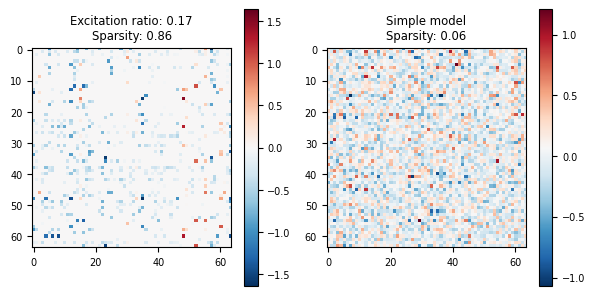

In [4]:
weight = ei_net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 0.9*max(np.max(weight), np.max(-weight))
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = ei_net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='RdBu_r')
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


## 4. Analyze Functional Complexity (Post-Training)

Now that both networks have been trained (or loaded), we analyze their functional complexity by measuring XORable subnetworks.


In [5]:
print("Analyzing EI-separated Network...")
ei_complexity = measure_functional_complexity_batch(
    ei_net, input_size, output_size, seq_len
)

print("\nAnalyzing SimpleNet...")
simple_complexity = measure_functional_complexity_batch(
    simple_net, input_size, output_size, seq_len
)

print("\n" + "="*50)
print("FUNCTIONAL COMPLEXITY RESULTS")
print("="*50)

print(f"\nEI-separated Network:")
# print(f"  Total subnetworks tested: {ei_complexity['total_subnetworks']}")
# print(f"  XORable subnetworks: {ei_complexity['xorable_subnetworks']}")
print(f"  Complexity ratio: {ei_complexity['complexity_ratio']:.4f}")

print(f"\nSimpleNet:")
# print(f"  Total subnetworks tested: {simple_complexity['total_subnetworks']}")
# print(f"  XORable subnetworks: {simple_complexity['xorable_subnetworks']}")
print(f"  Complexity ratio: {simple_complexity['complexity_ratio']:.4f}")

# Calculate relative improvement
if simple_complexity['complexity_ratio'] > 0:
    relative_improvement = (ei_complexity['complexity_ratio'] - simple_complexity['complexity_ratio']) / simple_complexity['complexity_ratio'] * 100
    print(f"\nRelative improvement (EI vs Simple): {relative_improvement:.2f}%")
else:
    print(f"\nAbsolute difference: {ei_complexity['complexity_ratio'] - simple_complexity['complexity_ratio']:.4f}")

Analyzing EI-separated Network...
Testing 1 input pairs with 1 output neurons...
Progress: 0/1 input pairs processed
is_xorable_position: tensor([ 2,  5, 19, 27, 30, 39, 44, 46], device='cuda:0')

Analyzing SimpleNet...
Testing 1 input pairs with 1 output neurons...
Progress: 0/1 input pairs processed

FUNCTIONAL COMPLEXITY RESULTS

EI-separated Network:
  Complexity ratio: 0.1250

SimpleNet:
  Complexity ratio: 0.0000

Absolute difference: 0.1250


## 5. Visualize Example XOR Tests


Examples of XORable subnetworks:

EI-separated Network - First XORable subnetwork:
Input neurons: [0, 1]

No XORable subnetworks found in SimpleNet


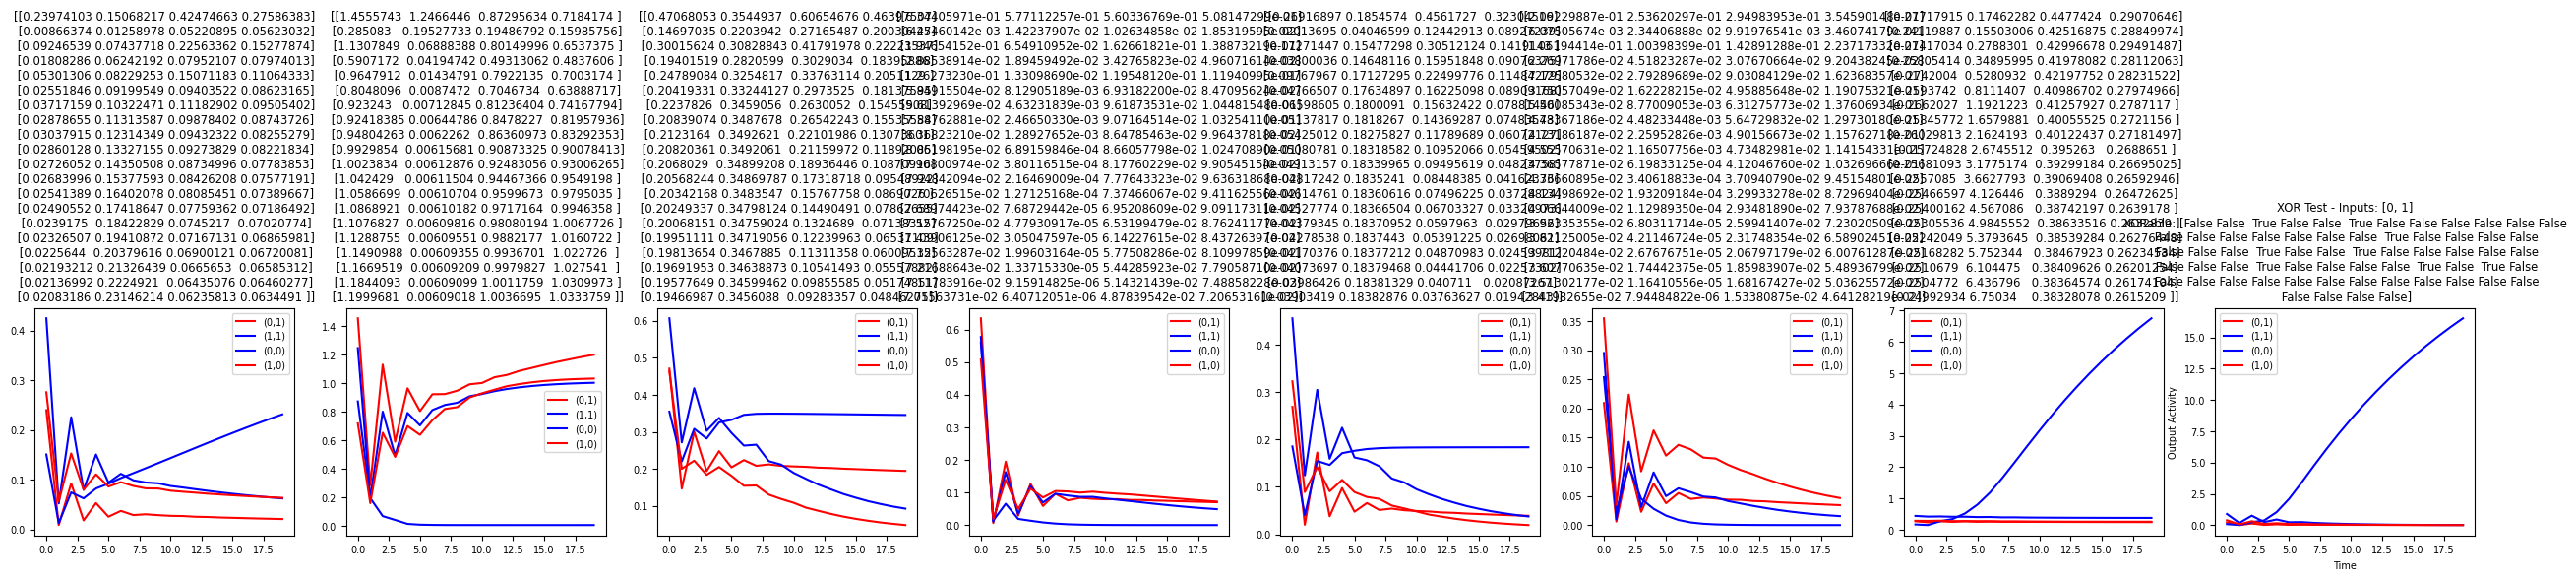

In [6]:
# Show examples of XORable subnetworks from each model
print("Examples of XORable subnetworks:")

if len(ei_complexity['xorable_details']) > 0:
    print(f"\nEI-separated Network - First XORable subnetwork:")
    example = ei_complexity['xorable_details'][0]
    print(f"Input neurons: {example['input_neurons']}")
    # print(f"Responses: {[f'{r:.3f}' for r in example['responses']]}")

    visualize_xor_example(example)
else:
    print("\nNo XORable subnetworks found in EI-separated Network")

if len(simple_complexity['xorable_details']) > 0:
    print(f"\nSimpleNet - First XORable subnetwork:")
    example = simple_complexity['xorable_details'][0]
    # print(f"Input neurons: {example['input_neurons']}, Output neuron: {example['output_neuron']}")
    # print(f"Responses: {[f'{r:.3f}' for r in example['responses']]}")

    visualize_xor_example(example)
else:
    print("\nNo XORable subnetworks found in SimpleNet")

## 6. Complexity Comparison Visualization


KeyError: 'xorable_subnetworks'

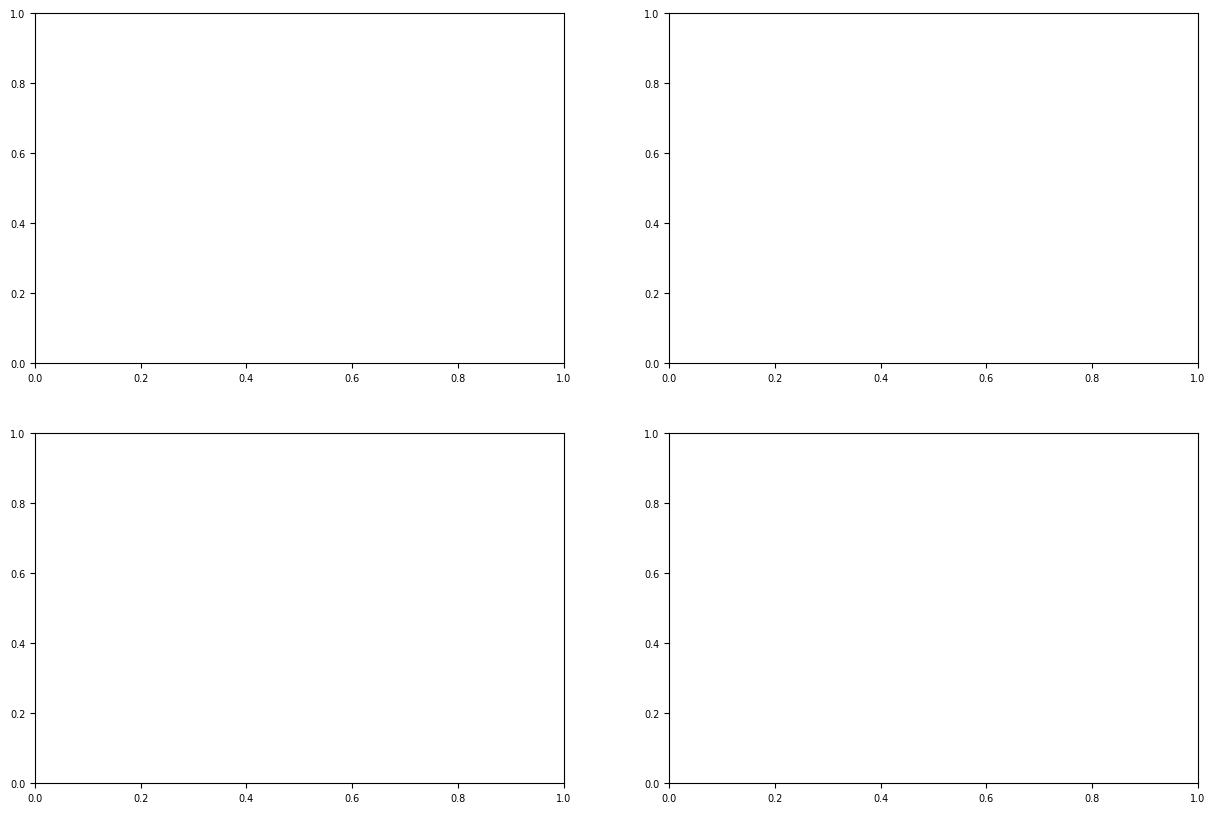

In [7]:
# Create comparison plots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# 1. Bar plot of XORable subnetworks count
models = ['EI-separated\nNetwork', 'SimpleNet']
xorable_counts = [ei_complexity['xorable_subnetworks'], simple_complexity['xorable_subnetworks']]
colors = ['blue', 'red']

bars1 = ax1.bar(models, xorable_counts, color=colors, alpha=0.7)
ax1.set_ylabel('Number of XORable Subnetworks')
ax1.set_title('XORable Subnetworks Count')
ax1.grid(True, alpha=0.3)

# Add value labels
for bar, count in zip(bars1, xorable_counts):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{count}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# 2. Bar plot of complexity ratios
complexity_ratios = [ei_complexity['complexity_ratio'], simple_complexity['complexity_ratio']]

bars2 = ax2.bar(models, complexity_ratios, color=colors, alpha=0.7)
ax2.set_ylabel('Complexity Ratio')
ax2.set_title('Functional Complexity Ratio')
ax2.grid(True, alpha=0.3)

# Add value labels
for bar, ratio in zip(bars2, complexity_ratios):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{ratio:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# 3. Distribution of XORable subnetworks by output neuron (EI-separated)
if len(ei_complexity['xorable_details']) > 0:
    ei_output_neurons = [detail['output_neuron'] for detail in ei_complexity['xorable_details']]
    ax3.hist(ei_output_neurons, bins=range(output_size+1), alpha=0.7, color='blue', edgecolor='black')
    ax3.set_xlabel('Output Neuron Index')
    ax3.set_ylabel('Number of XORable Subnetworks')
    ax3.set_title('XORable Subnetworks by Output Neuron (EI-separated)')
    ax3.grid(True, alpha=0.3)
else:
    ax3.text(0.5, 0.5, 'No XORable\nSubnetworks', ha='center', va='center', transform=ax3.transAxes)
    ax3.set_title('XORable Subnetworks by Output Neuron (EI-separated)')

# 4. Distribution of XORable subnetworks by output neuron (SimpleNet)
if len(simple_complexity['xorable_details']) > 0:
    simple_output_neurons = [detail['output_neuron'] for detail in simple_complexity['xorable_details']]
    ax4.hist(simple_output_neurons, bins=range(output_size+1), alpha=0.7, color='red', edgecolor='black')
    ax4.set_xlabel('Output Neuron Index')
    ax4.set_ylabel('Number of XORable Subnetworks')
    ax4.set_title('XORable Subnetworks by Output Neuron (SimpleNet)')
    ax4.grid(True, alpha=0.3)
else:
    ax4.text(0.5, 0.5, 'No XORable\nSubnetworks', ha='center', va='center', transform=ax4.transAxes)
    ax4.set_title('XORable Subnetworks by Output Neuron (SimpleNet)')

plt.tight_layout()
plt.show()

## 7. Detailed Analysis of Network Weights


Analyzing network weight structures...


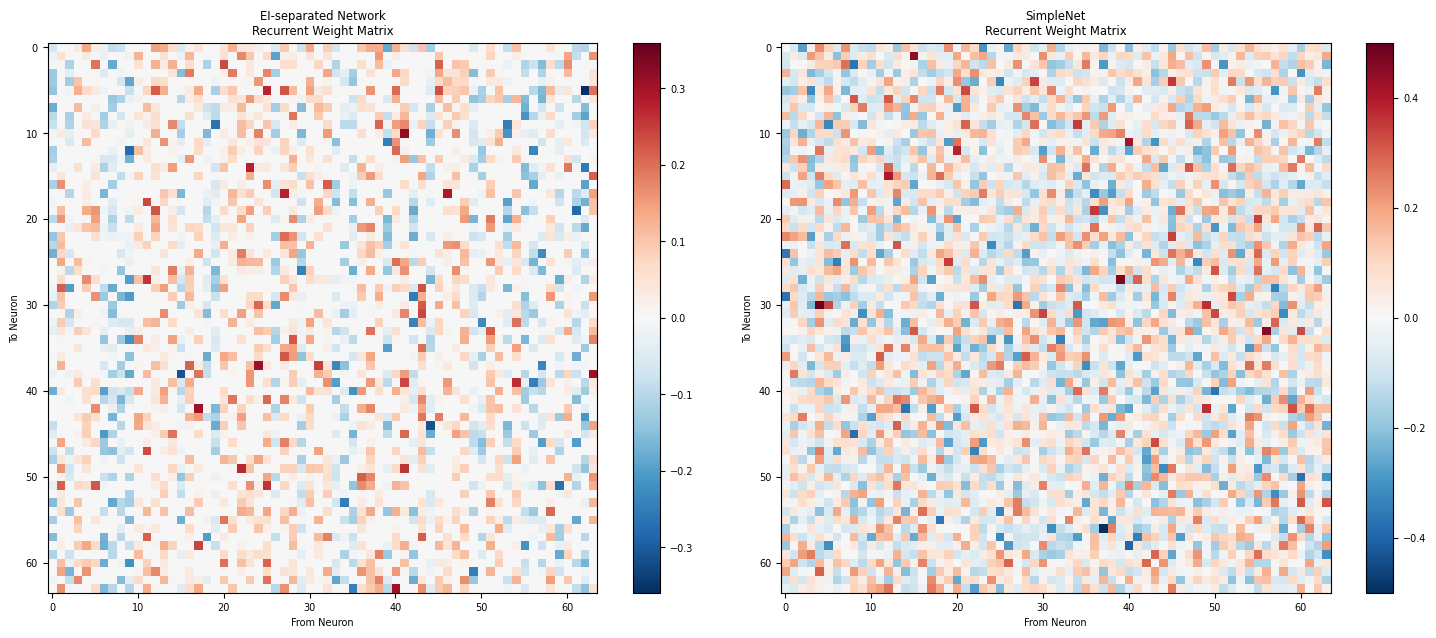


Weight Matrix Statistics:
EI-separated Network:
  Mean weight: 0.0064
  Std weight: 0.0695
  Positive weights: 1191/4096 (29.1%)
  Negative weights: 844/4096 (20.6%)

SimpleNet:
  Mean weight: 0.0028
  Std weight: 0.1240
  Positive weights: 2081/4096 (50.8%)
  Negative weights: 2015/4096 (49.2%)


In [ ]:
# Analyze the actual recurrent weight matrices
print("Analyzing network weight structures...")

# Get weight matrices
ei_weights = ei_net.get_actual_weight().detach().cpu().numpy()
simple_weights = simple_net.get_actual_weight().detach().cpu().numpy()

# Plot weight matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# EI-separated network weights
im1 = ax1.imshow(ei_weights, cmap='RdBu_r', vmin=-np.max(np.abs(ei_weights)), vmax=np.max(np.abs(ei_weights)))
ax1.set_title('EI-separated Network\nRecurrent Weight Matrix')
ax1.set_xlabel('From Neuron')
ax1.set_ylabel('To Neuron')
plt.colorbar(im1, ax=ax1)

# SimpleNet weights
im2 = ax2.imshow(simple_weights, cmap='RdBu_r', vmin=-np.max(np.abs(simple_weights)), vmax=np.max(np.abs(simple_weights)))
ax2.set_title('SimpleNet\nRecurrent Weight Matrix')
ax2.set_xlabel('From Neuron')
ax2.set_ylabel('To Neuron')
plt.colorbar(im2, ax=ax2)

plt.tight_layout()
plt.show()

# Analyze weight statistics
print(f"\nWeight Matrix Statistics:")
print(f"EI-separated Network:")
print(f"  Mean weight: {np.mean(ei_weights):.4f}")
print(f"  Std weight: {np.std(ei_weights):.4f}")
print(f"  Positive weights: {np.sum(ei_weights > 0)}/{ei_weights.size} ({np.sum(ei_weights > 0)/ei_weights.size*100:.1f}%)")
print(f"  Negative weights: {np.sum(ei_weights < 0)}/{ei_weights.size} ({np.sum(ei_weights < 0)/ei_weights.size*100:.1f}%)")

print(f"\nSimpleNet:")
print(f"  Mean weight: {np.mean(simple_weights):.4f}")
print(f"  Std weight: {np.std(simple_weights):.4f}")
print(f"  Positive weights: {np.sum(simple_weights > 0)}/{simple_weights.size} ({np.sum(simple_weights > 0)/simple_weights.size*100:.1f}%)")
print(f"  Negative weights: {np.sum(simple_weights < 0)}/{simple_weights.size} ({np.sum(simple_weights < 0)/simple_weights.size*100:.1f}%)")